# Task 1: Financial Data Extraction and Analysis
**BCG GenAI Job Simulation (Forage)**, prepared by Gibson Nyendwa

## Objective
Extract key financial figures from the 10-K annual reports of **Microsoft, Tesla and Apple**, analyse three years of trends, and prepare a clean dataset that the AI-powered financial chatbot (Task 2) can query.

## Data source and method
- Figures were taken by hand from each company's Form 10-K on **SEC EDGAR** (consolidated income statement, balance sheet and cash flow statement).
- Period: the three most recent fiscal years with full 10-K filings at the time of collection: **FY2022, FY2023 and FY2024**.
- All values are in **US$ millions**.
- Fiscal years differ: Microsoft ends 30 June, Apple ends late September, Tesla ends 31 December. Comparisons are therefore by fiscal year, not calendar year.
- Tesla's net income is *net income attributable to common stockholders*, as reported in its 10-K.

| Metric | Where it sits in the 10-K |
|---|---|
| Total Revenue | Income statement |
| Net Income | Income statement |
| Total Assets | Balance sheet |
| Total Liabilities | Balance sheet |
| Cash Flow from Operating Activities | Cash flow statement |

## 1. Load the extracted data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
DATA = Path("../data")
CHARTS = Path("../charts")
CHARTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "financial_data.csv")
df = df.sort_values(["Company", "Fiscal Year"]).reset_index(drop=True)
df

,Company,Fiscal Year,Fiscal Year End,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
0,Apple,2022,2022-09-24,394328,99803,352755,302083,122151
1,Apple,2023,2023-09-30,383285,96995,352583,290437,110543
2,Apple,2024,2024-09-28,391035,93736,364980,308030,118254
3,Microsoft,2022,2022-06-30,198270,72738,364840,198298,89035
4,Microsoft,2023,2023-06-30,211915,72361,411976,205753,87582
5,Microsoft,2024,2024-06-30,245122,88136,512163,243686,118548
6,Tesla,2022,2022-12-31,81462,12556,82338,36440,14724
7,Tesla,2023,2023-12-31,96773,14997,106618,43009,13256
8,Tesla,2024,2024-12-31,97690,7091,122070,48390,14923


## 2. Data cleaning and quality checks
Before analysing anything, confirm the data is complete, has no duplicates, uses consistent units and makes financial sense.

- **Missing values:** none expected; any found would be traced back to the 10-K rather than filled with estimates, because invented financial figures would undermine the chatbot's accuracy.
- **Duplicates:** each company and fiscal year must appear exactly once.
- **Consistent format:** every figure is in **US$ millions**, as reported in the 10-K, so no unit or currency conversion is needed.
- **Sense check:** liabilities should be below assets for these companies.

In [2]:
METRICS = ["Total Revenue", "Net Income", "Total Assets",
           "Total Liabilities", "Cash Flow from Operating Activities"]

print("Missing values:", int(df[METRICS].isna().sum().sum()))
print("Years per company:", df.groupby("Company")["Fiscal Year"].count().to_dict())
print("Duplicate company-year rows:", int(df.duplicated(subset=["Company", "Fiscal Year"]).sum()))
print("All metrics numeric:", all(pd.api.types.is_numeric_dtype(df[m]) for m in METRICS))
print("Liabilities below assets in every row:", bool((df["Total Liabilities"] < df["Total Assets"]).all()))
df[METRICS].describe()

Missing values: 0
Years per company: {'Apple': 3, 'Microsoft': 3, 'Tesla': 3}
Duplicate company-year rows: 0
All metrics numeric: True
Liabilities below assets in every row: True


,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
count,9.00,9.00,9.00,9.00,9.00
mean,"233,320.00","62,045.89","296,702.56","186,236.22","76,557.33"
std,"130,006.97","39,108.19","153,240.42","114,506.22","48,272.77"
min,"81,462.00","7,091.00","82,338.00","36,440.00","13,256.00"
25%,"97,690.00","14,997.00","122,070.00","48,390.00","14,923.00"
50%,"211,915.00","72,738.00","352,755.00","205,753.00","89,035.00"
75%,"383,285.00","93,736.00","364,980.00","290,437.00","118,254.00"
max,"394,328.00","99,803.00","512,163.00","308,030.00","122,151.00"


## 3. Year-on-year growth
`groupby` keeps each company's growth separate, and `pct_change` compares each year with the one before. The first year for each company has no prior year, so it shows as blank.

In [3]:
growth_cols = []
for metric in METRICS:
    col = f"{metric} Growth (%)"
    df[col] = df.groupby("Company")[metric].pct_change() * 100
    growth_cols.append(col)

df[["Company", "Fiscal Year"] + growth_cols].dropna()

,Company,Fiscal Year,Total Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Cash Flow from Operating Activities Growth (%)
1,Apple,2023,-2.80,-2.81,-0.05,-3.86,-9.50
2,Apple,2024,2.02,-3.36,3.52,6.06,6.98
4,Microsoft,2023,6.88,-0.52,12.92,3.76,-1.63
5,Microsoft,2024,15.67,21.80,24.32,18.44,35.36
7,Tesla,2023,18.80,19.44,29.49,18.03,-9.97
8,Tesla,2024,0.95,-52.72,14.49,12.51,12.58


## 4. Financial health ratios
- **Net profit margin**: how much of each dollar of revenue becomes profit.
- **Liabilities to assets**: how much of the asset base is funded by liabilities (a leverage indicator).
- **Operating cash flow to net income**: earnings quality. Above 1.0 means reported profit is backed by real cash.

In [4]:
df["Net Margin (%)"] = df["Net Income"] / df["Total Revenue"] * 100
df["Liabilities to Assets (%)"] = df["Total Liabilities"] / df["Total Assets"] * 100
df["OCF to Net Income (x)"] = df["Cash Flow from Operating Activities"] / df["Net Income"]

ratio_cols = ["Net Margin (%)", "Liabilities to Assets (%)", "OCF to Net Income (x)"]
df[["Company", "Fiscal Year"] + ratio_cols]

,Company,Fiscal Year,Net Margin (%),Liabilities to Assets (%),OCF to Net Income (x)
0,Apple,2022,25.31,85.64,1.22
1,Apple,2023,25.31,82.37,1.14
2,Apple,2024,23.97,84.40,1.26
3,Microsoft,2022,36.69,54.35,1.22
4,Microsoft,2023,34.15,49.94,1.21
5,Microsoft,2024,35.96,47.58,1.35
6,Tesla,2022,15.41,44.26,1.17
7,Tesla,2023,15.50,40.34,0.88
8,Tesla,2024,7.26,39.64,2.10


## 5. Three-year summary per company
Compound annual growth rate (CAGR) over the two growth periods gives one comparable number per company.

In [5]:
def cagr(series):
    first, last = series.iloc[0], series.iloc[-1]
    periods = len(series) - 1
    return ((last / first) ** (1 / periods) - 1) * 100

summary = df.groupby("Company").agg(
    revenue_cagr=("Total Revenue", cagr),
    net_income_cagr=("Net Income", cagr),
    avg_net_margin=("Net Margin (%)", "mean"),
    latest_liabilities_to_assets=("Liabilities to Assets (%)", "last"),
    avg_ocf_to_net_income=("OCF to Net Income (x)", "mean"),
)
summary.columns = ["Revenue CAGR (%)", "Net Income CAGR (%)", "Avg Net Margin (%)",
                   "Latest Liabilities to Assets (%)", "Avg OCF to Net Income (x)"]
summary

,Revenue CAGR (%),Net Income CAGR (%),Avg Net Margin (%),Latest Liabilities to Assets (%),Avg OCF to Net Income (x)
Company,,,,,
Apple,-0.42,-3.09,24.86,84.40,1.21
Microsoft,11.19,10.08,35.60,47.58,1.26
Tesla,9.51,-24.85,12.72,39.64,1.39


## 6. Visualising the trends

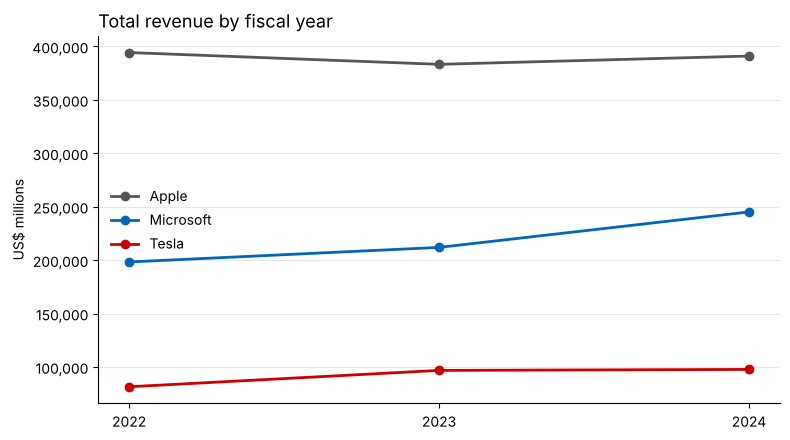

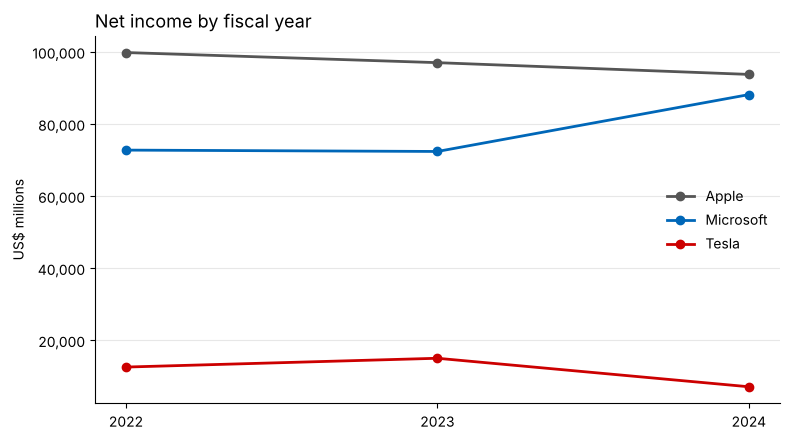

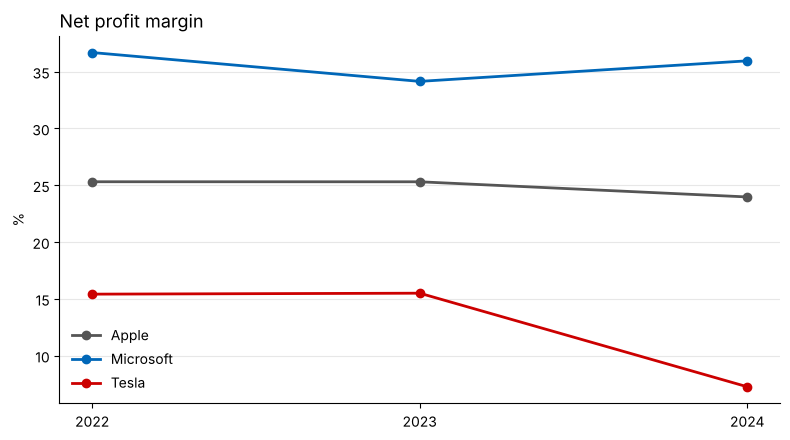

In [6]:
COLOURS = {"Apple": "#555555", "Microsoft": "#0067B8", "Tesla": "#CC0000"}

def plot_metric(column, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for company, data in df.groupby("Company"):
        ax.plot(data["Fiscal Year"], data[column], marker="o", linewidth=2,
                label=company, color=COLOURS[company])
    ax.set_title(title, fontsize=13, loc="left")
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xticks(sorted(df["Fiscal Year"].unique()))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(CHARTS / filename, dpi=150)
    plt.show()

plot_metric("Total Revenue", "Total revenue by fiscal year", "US$ millions", "revenue_trend.png")
plot_metric("Net Income", "Net income by fiscal year", "US$ millions", "net_income_trend.png")
plot_metric("Net Margin (%)", "Net profit margin", "%", "net_margin_trend.png")

## 7. Key insights

**Microsoft: strongest momentum.** Revenue rose from $198.3bn to $245.1bn (about 11% a year), with a 15.7% jump in FY2024. Net income grew 21.8% in FY2024 and margins stayed the highest of the three at roughly 34 to 37%. Total assets grew 24.3% in FY2024, largely reflecting the Activision Blizzard acquisition (goodwill rose from $67.9bn to $119.2bn). Leverage fell every year to 47.6% of assets.

**Apple: scale and stability, but flat growth.** Apple has by far the largest revenue base (about $391bn) but revenue dipped 2.8% in FY2023 and recovered only 2.0% in FY2024. Net income slipped in both years and the margin eased from 25.3% to 24.0%. Liabilities fund around 84% of assets, the highest of the three, which reflects Apple's long-running share buyback and dividend programme rather than distress. Operating cash flow consistently exceeds net income (1.14 to 1.26x).

**Tesla: growth has stalled and profit fell sharply.** Revenue grew 18.8% in FY2023 but only 0.9% in FY2024. Net income fell 52.7% to $7.1bn and the margin halved to 7.3%. Part of the FY2023 profit was a one-off tax benefit from releasing a valuation allowance on deferred tax assets, which flatters the comparison, but pricing pressure on vehicles also cut into margins. Tesla carries the lowest leverage (39.6%) and its operating cash flow in FY2024 was 2.1 times net income, so cash generation held up far better than reported profit.

**What this means for the chatbot.** The dataset is complete, consistent and stored in one tidy table, so the chatbot can look up any metric by company and year and compare against the prior year without further cleaning.

## 8. AI-ready preprocessing
The ratios in section 4 are the **feature engineering** step: they turn raw figures into financial health indicators. This section prepares the data for machine learning and time-series work as well as for the chatbot.

- **Lag features:** each company's prior-year values sit on the same row, so a model (or the chatbot) can compare years without extra lookups.
- **Encoding:** the company name is categorical, so it is one-hot encoded into numeric 0/1 columns that machine learning models can read.
- **Time index:** fiscal year stays as a number and rows are ordered by company then year, the standard layout for panel time-series data.
- **Inflation:** figures are kept in nominal US dollars. Over three years, inflation would not change any trend or ranking in this analysis, and the 10-K reports nominal values, so keeping them unadjusted preserves traceability to the source. Real-terms adjustment would matter for a longer history.
- **Seasonality:** not present in annual data. It becomes relevant once quarterly 10-Q data is added.

In [7]:
ml = df.copy()

LAG_METRICS = ["Total Revenue", "Net Income", "Cash Flow from Operating Activities"]
for metric in LAG_METRICS:
    ml[f"{metric} (Prior Year)"] = ml.groupby("Company")[metric].shift(1)

company_dummies = pd.get_dummies(ml["Company"], prefix="Company", dtype=int)
ml = pd.concat([ml, company_dummies], axis=1)

lag_cols = [f"{m} (Prior Year)" for m in LAG_METRICS]
ml[["Company", "Fiscal Year"] + LAG_METRICS[:1] + lag_cols[:1] + list(company_dummies.columns)]

,Company,Fiscal Year,Total Revenue,Total Revenue (Prior Year),Company_Apple,Company_Microsoft,Company_Tesla
0,Apple,2022,394328,NaN,1,0,0
1,Apple,2023,383285,"394,328.00",1,0,0
2,Apple,2024,391035,"383,285.00",1,0,0
3,Microsoft,2022,198270,NaN,0,1,0
4,Microsoft,2023,211915,"198,270.00",0,1,0
5,Microsoft,2024,245122,"211,915.00",0,1,0
6,Tesla,2022,81462,NaN,0,0,1
7,Tesla,2023,96773,"81,462.00",0,0,1
8,Tesla,2024,97690,"96,773.00",0,0,1


## 9. Export for the chatbot and for Excel

In [8]:
df.round(2).to_csv(DATA / "financial_analysis.csv", index=False)

with pd.ExcelWriter(DATA / "BCG_GenAI_Task1_Financial_Analysis.xlsx", engine="openpyxl") as writer:
    df[["Company", "Fiscal Year", "Fiscal Year End"] + METRICS].to_excel(writer, sheet_name="Raw 10-K Data", index=False)
    df[["Company", "Fiscal Year"] + growth_cols].round(2).to_excel(writer, sheet_name="YoY Growth", index=False)
    df[["Company", "Fiscal Year"] + ratio_cols].round(2).to_excel(writer, sheet_name="Ratios", index=False)
    summary.round(2).to_excel(writer, sheet_name="Summary")
    for ws in writer.book.worksheets:
        for col in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col) + 2
            ws.column_dimensions[col[0].column_letter].width = min(width, 45)
        ws.freeze_panes = "A2"

ml.round(2).to_csv(DATA / "financial_features_ml.csv", index=False)

print("Saved financial_analysis.csv, financial_features_ml.csv and BCG_GenAI_Task1_Financial_Analysis.xlsx")

Saved financial_analysis.csv, financial_features_ml.csv and BCG_GenAI_Task1_Financial_Analysis.xlsx
